In [ ]:
#LE NET -5 CNN FOR MNIST CLASSIFICATION
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import Conv2D, AveragePooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt


# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras import models, layers

In [ ]:
#Load MNIST Data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


In [ ]:
x_train=x_train/255.0
x_test=x_test/255.0
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [ ]:
#Adding Channel Dimension
x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [ ]:
#Creating LE NET -5 CNN
model=Sequential([
    #C1 Convolution
    layers.Conv2D(6,kernel_size=(5,5),activation='tanh',input_shape=(28,28,1)),
    #P1 Pooling
    layers.AveragePooling2D(pool_size=(2,2)),
    #C2 Convolution
    layers.Conv2D(16,kernel_size=(5,5),activation='tanh'),
    #P2 Pooling
    layers.AveragePooling2D(pool_size=(2,2)),
    #Flatten
    layers.Flatten(),
    #Fully Connected Layer
    layers.Dense(120,activation='tanh'),
    layers.Dense(84,activation='tanh'),
    #output Layer
    layers.Dense(10,activation='softmax')
    ])

In [ ]:
# model=Sequential()
# model.add(Conv2D(6,kernel_size=(5,5),activation='tanh',input_shape=(28,28,1)))
# model.add(MaxPooling2D(pool_size=(2,2)))
# model.add(Conv2D(16,kernel_size=(5,5),activation='tanh'))
# model.add(MaxPooling2D(pool_size=(2,2)))
# model.add(Flatten())
# model.add

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Compile The Model
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
#Training The Model
history=model.fit(x_train,y_train,epochs=10,batch_size=128, validation_split=0.1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.8925 - loss: 0.3744 - val_accuracy: 0.9607 - val_loss: 0.1402
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 56ms/step - accuracy: 0.9567 - loss: 0.1395 - val_accuracy: 0.9748 - val_loss: 0.0936
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - accuracy: 0.9729 - loss: 0.0904 - val_accuracy: 0.9778 - val_loss: 0.0752
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - accuracy: 0.9794 - loss: 0.0669 - val_accuracy: 0.9842 - val_loss: 0.0577
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.9829 - loss: 0.0542 - val_accuracy: 0.9833 - val_loss: 0.0604
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - accuracy: 0.9869 - loss: 0.0432 - val_accuracy: 0.9850 - val_loss: 0.0540
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - accuracy: 0.9882 - loss: 0.0373 - val_accuracy: 0.9855 - val_loss: 0.0536
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - accuracy: 0.9896 - loss: 0.0324 - 

In [ ]:
#Test The Model
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Test Accuracy: {test_accuracy * 100:.2f}%')

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9822 - loss: 0.0604
Test Accuracy: 98.22%


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Predicted Digit 7
Actual Digit 7


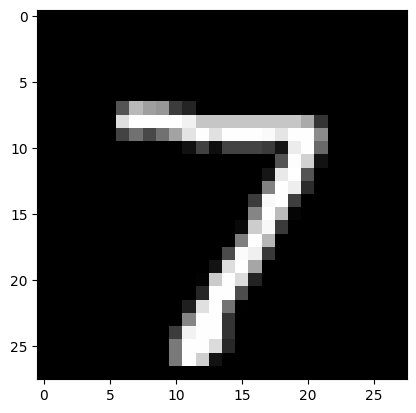

In [ ]:
#Making Predictions
predictions = model.predict(x_test)
print("Predicted Digit", np.argmax(predictions[0]))
print("Actual Digit",y_test[0])
plt.imshow(x_test[0].reshape(28, 28), cmap='gray')
plt.show()

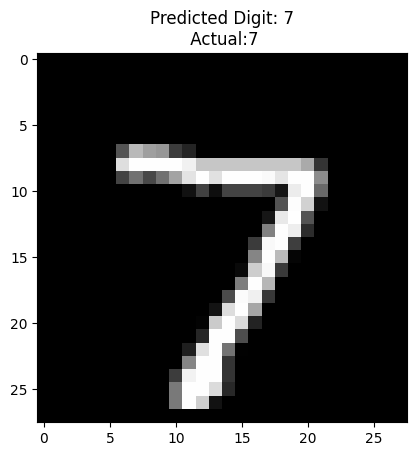

In [ ]:
plt.imshow(x_test[0].reshape(28, 28), cmap='gray')
plt.title(f'Predicted Digit: {np.argmax(predictions[0])}\n Actual:{y_test[0]}')
plt.show()